# Baker Street Text Lab
## Comparing recurrent networks on Sherlock Holmes

Build and inspect four word-level next-token predictors: **Simple RNN, Bidirectional RNN, LSTM, and GRU**. This notebook explains the pipeline, loads the saved experiment, plots measured results, and generates new continuations.

Inspired by [the reference project](https://github.com/anuranbaruah/Sherlock-Holmes-RNN-text-generation). The implementation and measured results belong to this project. Dataset: [Project Gutenberg #1661](https://www.gutenberg.org/ebooks/1661), Arthur Conan Doyle's *The Adventures of Sherlock Holmes*.

Run cells in order with the project's Python environment. Install `requirements-dev.txt` first. The default walkthrough uses `results/demo`; change `TRAIN_MODELS` below to train again.

In [1]:
from pathlib import Path
import csv
import json
import sys
import subprocess
from datetime import datetime
import torch
from IPython.display import display, Markdown, Image

ROOT = Path.cwd().resolve()
if not (ROOT / "sherlock").is_dir():
    raise RuntimeError("Open this notebook from the sherlock-text-generator directory.")
sys.path.insert(0, str(ROOT))
torch.set_num_threads(2)
from sherlock.data import DATA_PATH, download_book, clean_book, tokenize, prepare_data, detokenize
from sherlock.model import MODEL_NAMES, ModelConfig, NextWordModel
from sherlock.generation import load_model, generate, diversity_metrics
print("PyTorch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())

PyTorch: 2.14.1+cpu | CUDA available: False


## 1. Inspect the dataset

The original text, including its Gutenberg notice, remains unchanged on disk. For modeling, wrappers and front matter are removed in memory. The tokenizer lowercases text, preserves contractions, and separates common punctuation. Punctuation counts as tokens.

In [2]:
download_book(DATA_PATH)
raw = DATA_PATH.read_text(encoding="utf-8-sig")
book = clean_book(raw)
tokens = tokenize(book)
print(f"Clean characters: {len(book):,}")
print(f"Word/punctuation tokens: {len(tokens):,}")
print("\nOpening:\n", book[:500])

Clean characters: 562,202
Word/punctuation tokens: 120,630

Opening:
 The Adventures of Sherlock Holmes

by Arthur Conan Doyle


Contents

   I.     A Scandal in Bohemia
   II.    The Red-Headed League
   III.   A Case of Identity
   IV.    The Boscombe Valley Mystery
   V.     The Five Orange Pips
   VI.    The Man with the Twisted Lip
   VII.   The Adventure of the Blue Carbuncle
   VIII.  The Adventure of the Speckled Band
   IX.    The Adventure of the Engineer’s Thumb
   X.     The Adventure of the Noble Bachelor
   XI.    The Adventure of the Beryl Coronet
 


## 2. Split first, then build the vocabulary and windows

The stream is divided sequentially into **80% training, 10% validation, and 10% test**. The vocabulary is fitted only on the training split; rare words and unseen held-out words become `<unk>`. A 20-token window predicts the next token. Windows never cross split boundaries, avoiding overlapping-window leakage.

In [3]:
vocabulary, datasets, summary = prepare_data(DATA_PATH, context_length=20)
print(json.dumps({key: summary[key] for key in ("total_tokens", "vocabulary_size", "split_boundaries", "splits")}, indent=2))
context, target = datasets["train"][0]
print("\nInput: ", detokenize([vocabulary.tokens[index] for index in context.tolist()]))
print("Target:", vocabulary.tokens[int(target)])

{
  "total_tokens": 120630,
  "vocabulary_size": 3926,
  "split_boundaries": [
    0,
    96504,
    108567,
    120630
  ],
  "splits": {
    "train": {
      "tokens": 96504,
      "sequences": 96484,
      "unknown_rate": 0.03508662853353229
    },
    "validation": {
      "tokens": 12063,
      "sequences": 12043,
      "unknown_rate": 0.060598524413495815
    },
    "test": {
      "tokens": 12063,
      "sequences": 12043,
      "unknown_rate": 0.07170687225399984
    }
  }
}

Input:  the adventures of sherlock holmes by <unk> <unk> <unk> contents i. a scandal in bohemia ii. the red
Target: headed


## 3. Compare the recurrent architectures

Every architecture uses `Embedding → recurrent block → Dropout → Linear(vocabulary)`.

- **Simple RNN:** a tanh recurrent baseline.
- **Bidirectional RNN:** processes the observed past context in both directions. Its target word is never supplied as an input. Final forward and backward hidden states are concatenated.
- **LSTM:** gated updates and a separate cell state.
- **GRU:** gated updates with a single hidden state.

Shared hidden sizes do not imply equal parameter counts. This comparison holds hyperparameters constant, not the total number of parameters.

In [4]:
for kind, label in MODEL_NAMES.items():
    model = NextWordModel(ModelConfig(kind, len(vocabulary)))
    with torch.no_grad():
        logits = model(context.unsqueeze(0))
    print(f"{label:20} | {model.parameter_count:>9,} parameters | logits {tuple(logits.shape)}")

Simple RNN           |   782,550 parameters | logits (1, 3926)
Bidirectional RNN    | 1,309,910 parameters | logits (1, 3926)
LSTM                 |   857,046 parameters | logits (1, 3926)
GRU                  |   832,214 parameters | logits (1, 3926)


## 4. Load the demo or train a fresh run

Set `TRAIN_MODELS = True` to train all four architectures on the full book. A fresh timestamped folder protects previous results. CPU training may take several minutes or longer. Each model uses the same seed, sample order, optimizer, and hyperparameters. Early stopping uses validation loss; the best checkpoint is restored before test evaluation.

To reproduce a larger architecture, change the command to use `--embedding-dim 128 --hidden-dim 256 --layers 2 --epochs 25`.

In [5]:
TRAIN_MODELS = False
RUN_DIR = ROOT / "results" / "demo"
if TRAIN_MODELS:
    RUN_DIR = ROOT / "results" / datetime.now().strftime("notebook-%Y%m%d-%H%M%S")
    subprocess.run([sys.executable, str(ROOT / "train.py"), "--output", str(RUN_DIR),
                    "--epochs", "8", "--batch-size", "256", "--threads", "4"], check=True)
if not (RUN_DIR / "run.json").exists():
    raise RuntimeError("No saved run found. Set TRAIN_MODELS = True and rerun this cell.")
run = json.loads((RUN_DIR / "run.json").read_text())
if run["status"] != "complete":
    raise RuntimeError("This run is still training. Wait for completion before continuing.")
print("Experiment:", RUN_DIR.name)
print("Device:", run["device"])
print("Selected by validation loss:", MODEL_NAMES[run["recommended_model"]])

Experiment: demo
Device: cpu
Selected by validation loss: GRU


## 5. Evaluate on held-out text

Perplexity is `exp(mean cross-entropy)`; lower is better. Top-1 and top-5 accuracy include punctuation and unknown-token targets. Use `dataset.json` to inspect unknown rates. Compare perplexity only under the same vocabulary and preprocessing. The recommended model is selected by validation loss, not by picking the lowest test score.

| Model | Best epoch | Val loss | Test perplexity | Top-1 | Top-5 | Training (s) |
|---|---:|---:|---:|---:|---:|---:|
| Simple RNN | 7 | 4.531 | 87.7 | 18.7% | 42.5% | 238.5 |
| Bidirectional RNN | 5 | 4.648 | 97.9 | 18.3% | 41.2% | 179.2 |
| LSTM | 8 | 4.506 | 85.9 | 19.4% | 42.6% | 334.7 |
| GRU | 8 | 4.462 | 82.6 | 19.8% | 43.4% | 470.3 |


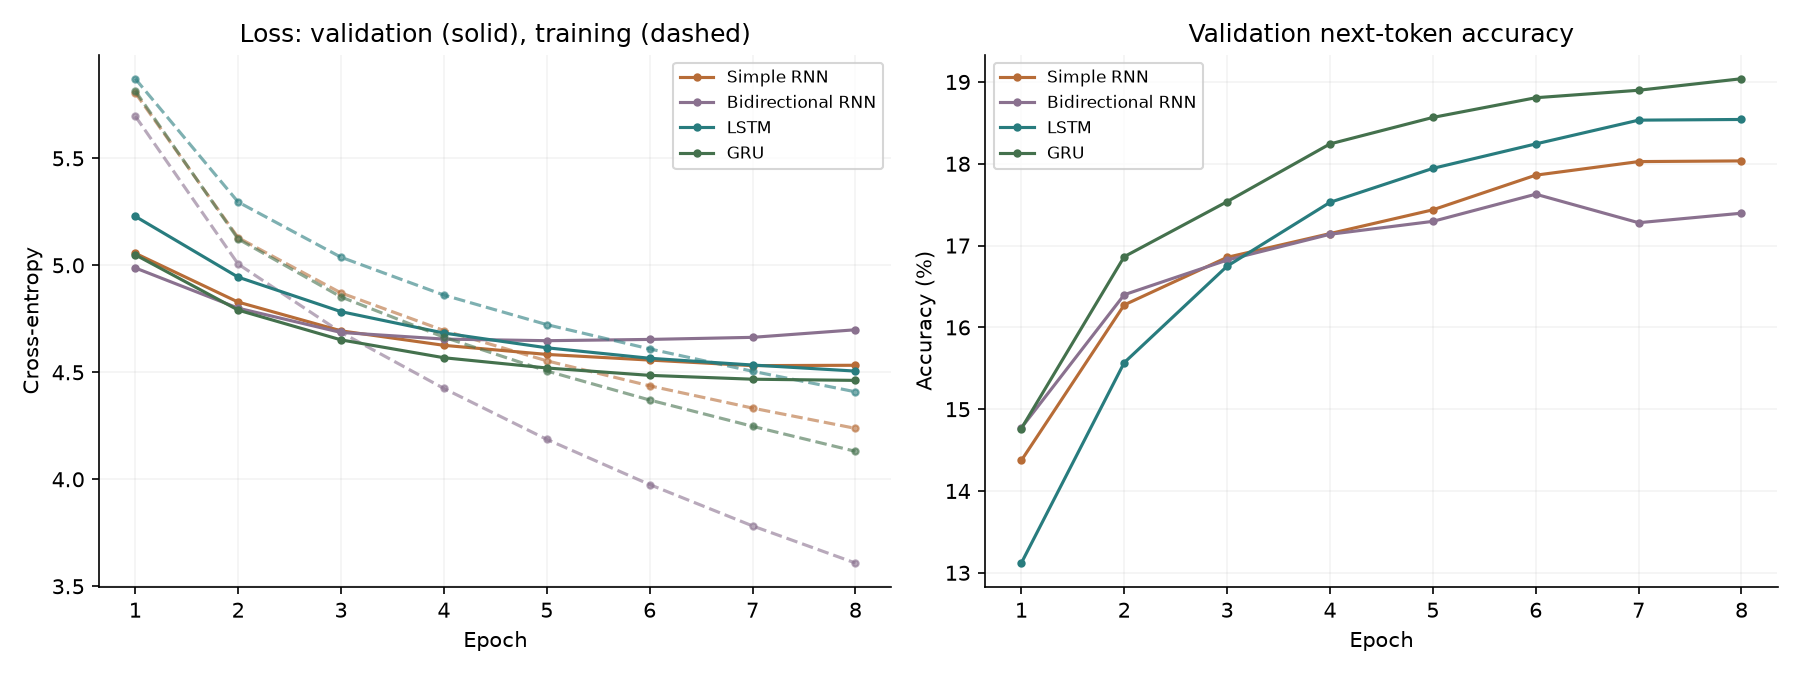

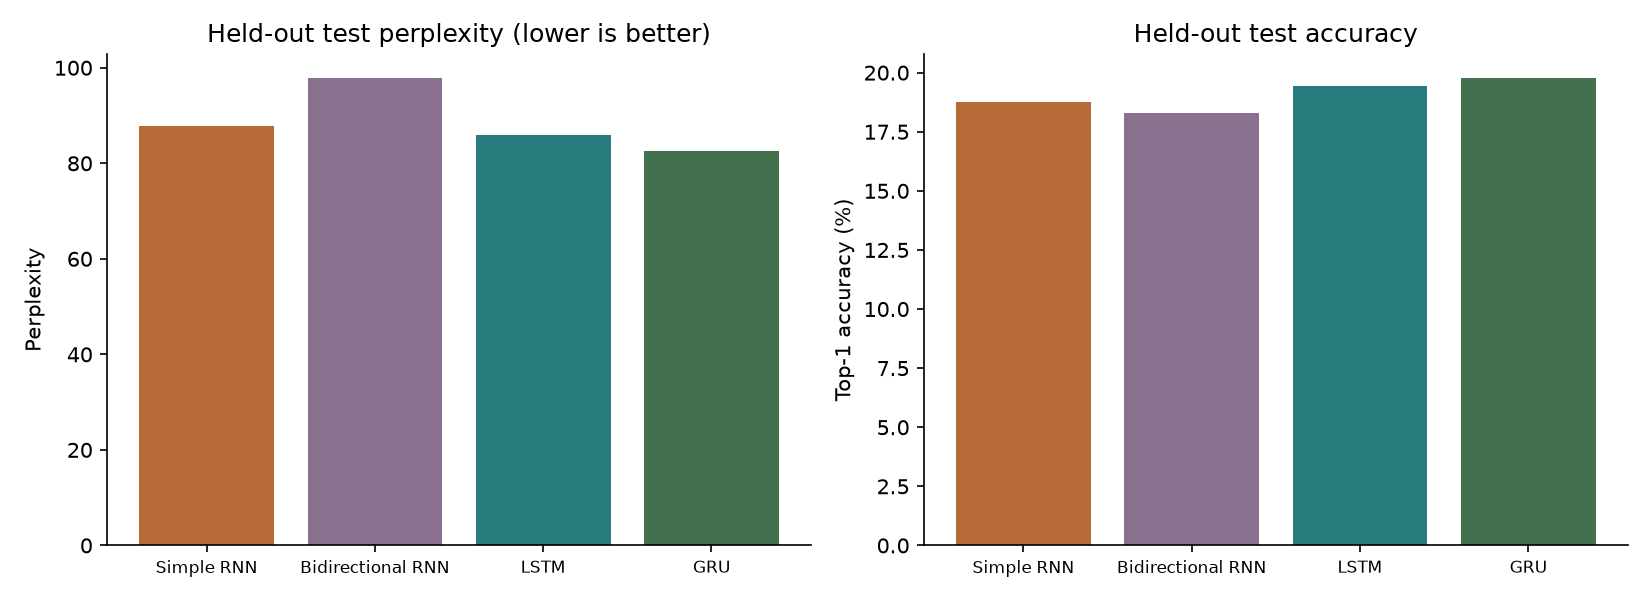

In [6]:
comparison = json.loads((RUN_DIR / "comparison.json").read_text())
table = "| Model | Best epoch | Val loss | Test perplexity | Top-1 | Top-5 | Training (s) |\n|---|---:|---:|---:|---:|---:|---:|\n"
for row in comparison:
    table += f"| {MODEL_NAMES[row['model']]} | {row['best_epoch']} | {row['validation_loss']:.3f} | {row['test_perplexity']:.1f} | {row['test_accuracy']:.1%} | {row['test_top5_accuracy']:.1%} | {row['training_seconds']:.1f} |\n"
display(Markdown(table))
display(Image(filename=str(RUN_DIR / "plots/training_curves.png")))
display(Image(filename=str(RUN_DIR / "plots/model_comparison.png")))

## 6. Generate new text

Choose a checkpoint and prompt. A local random generator makes repeated requests reproducible on the same environment. `<pad>` and `<unk>` are never sampled. Unknown prompt words are reported. These are small language models: grammatical fragments and repetition are expected, and a fluent phrase does not imply story-level reasoning.

In [7]:
selected = run["recommended_model"]
model, vocabulary, checkpoint = load_model(RUN_DIR / "checkpoints" / f"{selected}.pt")
result = generate(model, vocabulary,
                  prompt="Sherlock Holmes looked at me and said",
                  new_tokens=70, temperature=0.8, top_k=40, top_p=0.95, seed=42)
print(result["text"])
print("\nUnknown prompt words:", result["unknown_prompt_tokens"])
print("Continuation metrics:", diversity_metrics(result["continuation"]))

Sherlock Holmes looked at me and said. it is the honour for the window. i think i have a little man to my uncle to say that the man would have been left to night the machine. well, however, i have seen the two mccarthys by the window and made my way that we shall be no doubt, i remarked. there were one of my life that the lady,

Unknown prompt words: []
Continuation metrics: {'distinct_1': 0.6935483870967742, 'distinct_2': 0.9508196721311475, 'repeated_trigrams': 0.0}


## 7. Isolate the effect of temperature

Use identical prompts and random seeds at four temperatures. Disable top-k/top-p for this experiment so only temperature changes. Low temperature can cause loops; high temperature can increase variety at the expense of grammar. Distinct-word and repeated-trigram ratios describe diversity, not semantic coherence.


Temperature 0.2:
the inspector opened the door and found the lamp of the wood of the lamp, and the lamp was a small man, and the door was a small man who was a small man, and i was not a very busy, and i



Temperature 0.5:
the inspector opened the door and found upon the top of the door. her stepfather, said holmes, you would see that it is very much. i think that i have a little man in the matter. i shall put me for you



Temperature 1.0:
the inspector opened the door and found upon the top of the savannah whom her cripple reaches. here can you break for the time against the money, the usually which may be such a barred woman, sherlock holmes, he impulse. india,



Temperature 1.5:
the inspector opened the door and found upon eleven vanished ulster rope savannah out her recovered reaches. here can you break foresight to frighten things conduct money emerged beautifully from any young carbuncle such helen. i speak sherlock my slang he impulse. india know


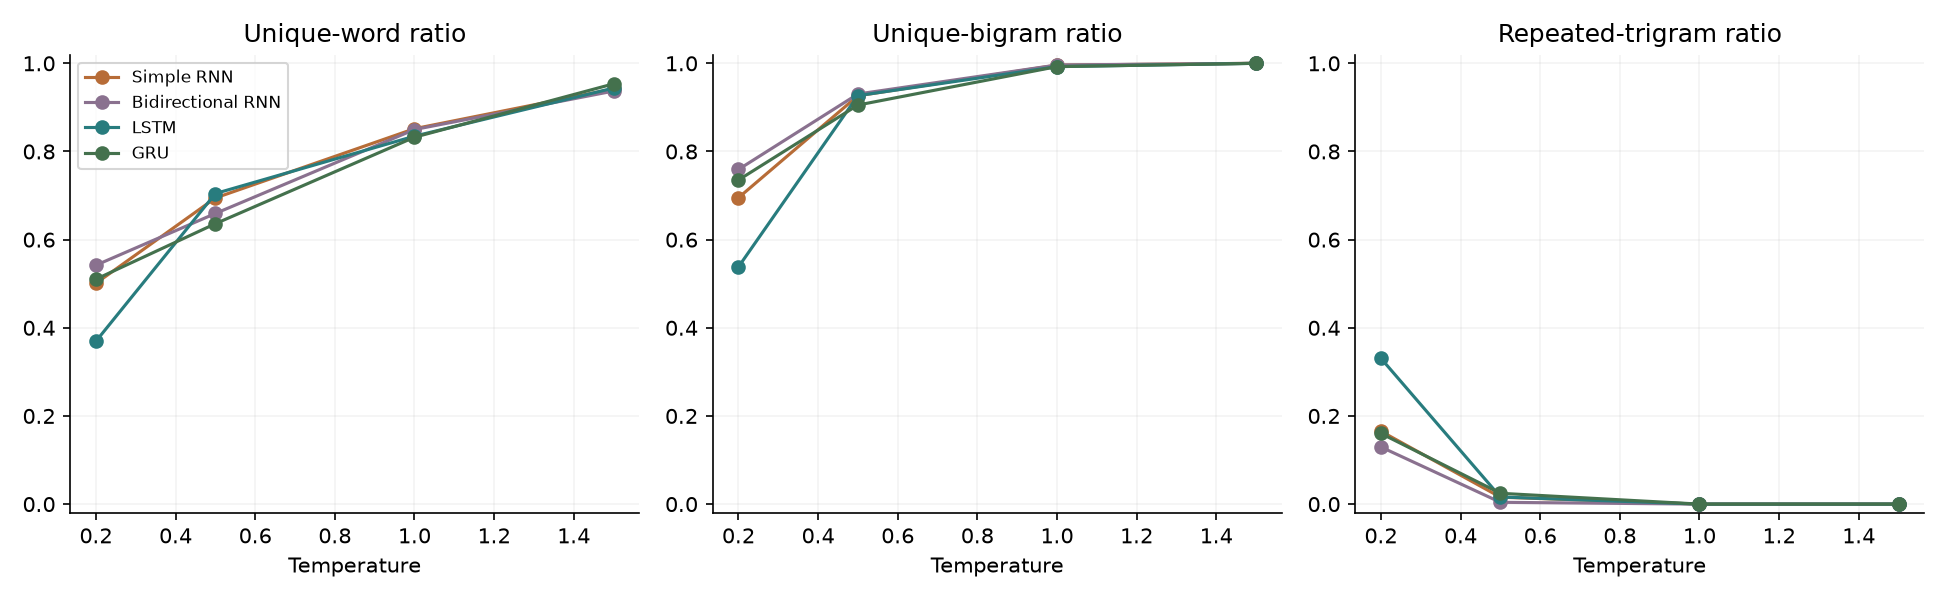

In [8]:
prompt = "the inspector opened the door and found"
for temperature in (0.2, 0.5, 1.0, 1.5):
    sample = generate(model, vocabulary, prompt, new_tokens=40,
                      temperature=temperature, top_k=0, top_p=1.0, seed=1000)
    print(f"\nTemperature {temperature}:\n{sample['text']}")
display(Image(filename=str(RUN_DIR / "plots/temperature_effects.png")))

## 8. Inspect the experiment's conclusions

The report is generated from this run's measured metrics and unedited samples. Inspect numerical performance and generated language together. There is one book and one training seed, so the run does not establish a general ranking of architectures. Repeat across several seeds for a stronger comparison.

In [9]:
report = (RUN_DIR / "REPORT.md").read_text(encoding="utf-8")
# Images are already displayed above; keep this output focused on measured conclusions and samples.
display(Markdown("\n".join(line for line in report.splitlines() if not line.startswith("!["))))

# Experiment report

Created: 2026-10-17T19:22:14.516906+00:00

Training device: `cpu`. Corpus: 120,630 tokens. Vocabulary: 3,926 tokens fitted only on the training split.

The token stream is split sequentially 80%/10%/10% before sliding windows are constructed. The vocabulary includes an unknown token; test metrics include unknown-token targets. See dataset.json for each split's unknown rate. Perplexity measures this tokenized vocabulary, so it should only be compared between runs with the same preprocessing and vocabulary.

| Model | Best epoch | Validation loss | Test loss | Test perplexity | Top-1 | Top-5 | Training (s) |
|---|---:|---:|---:|---:|---:|---:|---:|
| Simple RNN | 7 | 4.531 | 4.474 | 87.7 | 18.7% | 42.5% | 238.5 |
| Bidirectional RNN | 5 | 4.648 | 4.584 | 97.9 | 18.3% | 41.2% | 179.2 |
| LSTM | 8 | 4.506 | 4.454 | 85.9 | 19.4% | 42.6% | 334.7 |
| GRU | 8 | 4.462 | 4.414 | 82.6 | 19.8% | 43.4% | 470.3 |

**Selected model: GRU**, based on the lowest validation loss. Test results are reported after selection of each model's best validation checkpoint.



## Temperature experiment

All models use the same three prompts, temperatures (0.2, 0.5, 1.0, 1.5), and sampling seeds. Top-k and top-p filtering are disabled here to isolate temperature. Diversity and repetition metrics are descriptive; they do not establish story coherence or factual accuracy.


## Unedited generated samples

### Simple RNN at temperature 0.5

Prompt: sherlock holmes looked at me and said

> he was an ulster, and i have a sovereign that the man was not for the time of the case of the way, and my sister. they are all that i am to be a little of the case of the hotel, said he, the

### Simple RNN at temperature 1.0

Prompt: sherlock holmes looked at me and said

> upon the young ulster rope savannah my her avenue, and a hundred carbuncle would was over with the conduct. holmes! usually the note, you have been in her sherlock holmes, he might. for know perhaps, then very features, said it, the

### Bidirectional RNN at temperature 0.5

Prompt: sherlock holmes looked at me and said

> he and his eyes shining the first, and the lady of the church, and i had no doubt that the other was a very much indebted to the window, which i am afraid in the case, and i came very well, said holmes, and

### Bidirectional RNN at temperature 1.0

Prompt: sherlock holmes looked at me and said

> upon his mouth. but savannah my her cripple, feeling, i was not for that he had conduct money the curious than which i saw you have been in her mistress my friend he might prove for know mark. there's very features, said holmes, the

### LSTM at temperature 0.5

Prompt: sherlock holmes looked at me and said

> he was an ulster in the first, and the name of the other would have a few minutes with the room. i have seen my own, but i have no doubt, he remarked. i know that i came to do, said holmes, and

### LSTM at temperature 1.0

Prompt: sherlock holmes looked at me and said

> upon his mouth. but savannah my her cripple for mrs. k. try was to ask you conduct. holmes! usually over into my uncle, they in her mistress my father he impulse. india know perhaps, then very features, said he, and

### GRU at temperature 0.5

Prompt: sherlock holmes looked at me and said

> he. no, but i have her back for the case. you have seen to the police. you have no doubt that you will do you. i have no doubt you to say. i know that i have very much to this matter. i

### GRU at temperature 1.0

Prompt: sherlock holmes looked at me and said

> upon his mouth. but savannah out her back for me, i was surprised for that than things conduct. the whole usually over into my face, they found her sherlock my father he might save for upon the other of very features, and it had sister

## Interpretation and limitations

These small models learn local vocabulary and phrase patterns, but can repeat themselves and lose long-range meaning. A few epochs on a CPU are a demonstration, not evidence of polished story generation. Unknown words, a single book, a fixed context window, and a single training seed limit this experiment. Accuracy includes punctuation. Model sizes differ even when hidden dimensions are equal. Training times include validation and checkpoint writes and reflect current machine load; they are not controlled speed benchmarks. More rigorous comparisons should repeat training with several seeds and report uncertainty.

Inspect the actual samples alongside loss and perplexity; do not infer human-level writing quality from either metric.

## 9. Open the writing room

From a terminal in the project folder:

```bash
python app.py --run-dir results/demo
```

Open http://127.0.0.1:5001. For a fresh notebook experiment, pass the `RUN_DIR` displayed above.

**Ideas to investigate:** longer context windows; repeated training seeds; equal-parameter comparisons; the complete Holmes corpus; tokenization choices; larger gated models; comparison with a causal Transformer. Avoid selecting hyperparameters using the test split.

The book remains covered by its original Gutenberg notice. Project code is MIT licensed; see `LICENSE` and `data/SOURCE.md`.